**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 4**
Exploración de datos

---

*   NOMBRE: Oliver Ulises Fajardo Calderón
*   MATRÍCULA: A01610928


En esta actividad trabajarás con el archivo `personal_loan.csv`, basado en un conjunto de datos sobre clientes bancarios y su comportamiento financiero disponible en Kaggle.

Los datos fueron recopilados para analizar la posibilidad de que los clientes acepten un préstamo personal y contienen información demográfica, financiera y de productos bancarios asociados. Los indicadores incluidos son:

* `ID`: Identificador único del cliente
* `Age`: Edad del cliente (años completos)
* `Experience`: Experiencia laboral en años
* `Income`: Ingreso anual del cliente (en miles de dólares. Por ejemplo, 60 = 60,000 USD/año)
* `ZIP Code`: Código postal del cliente
* `Family`: Número de miembros de la familia
* `CCAvg`: Promedio de gastos mensuales con tarjeta de crédito (en miles de dólares)
* `Education`: Nivel educativo (1 = graduado, 2 = universitario, 3 = posgrado)
* `Mortgage`: Monto de hipoteca que posee el cliente (en miles de dólares)
* `Securities Account`: Indicador de si tiene cuenta de valores (1 = sí, 0 = no)
* `CD Account`: Indicador de si tiene cuenta de certificado de depósito (1 = sí, 0 = no)
* `Online`: Indicador de si usa los servicios bancarios en línea (1 = sí, 0 = no)
* `CreditCard`: Indicador de si es titular de tarjeta de crédito (1 = sí, 0 = no)
* `Personal Loan`: Si el cliente aceptó (1) o no (0) un préstamo personal. Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [1]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from IPython.display import display


1. Descarga el archivo: `personal_loan.csv` y guarda, en un dataframe (`loan_df`), todos sus registros.
* Haz que la columna `ID` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?

In [2]:
loan_df = pd.read_csv("personal_loan.csv", index_col="ID")
filas_iniciales = len(loan_df)

loan_df.info()

columnas_numericas_iniciales = loan_df.select_dtypes(include=np.number).columns.tolist()
columnas_texto_iniciales = loan_df.select_dtypes(include="object").columns.tolist()

print("\nColumnas numéricas:", len(columnas_numericas_iniciales), columnas_numericas_iniciales)
print("Columnas de texto:", len(columnas_texto_iniciales), columnas_texto_iniciales)


<class 'pandas.core.frame.DataFrame'>
Index: 5037 entries, 0 to 5036
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 5037 non-null   int64  
 1   Experience          5037 non-null   int64  
 2   Income              5037 non-null   int64  
 3   ZIP Code            5037 non-null   int64  
 4   Family              5037 non-null   int64  
 5   CCAvg               5037 non-null   float64
 6   Education           5037 non-null   float64
 7   Mortgage            5037 non-null   int64  
 8   Personal Loan       5037 non-null   object 
 9   Securities Account  5037 non-null   object 
 10  CD Account          5037 non-null   object 
 11  Online              5037 non-null   object 
 12  CreditCard          5037 non-null   object 
dtypes: float64(2), int64(6), object(5)
memory usage: 550.9+ KB

Columnas numéricas: 8 ['Age', 'Experience', 'Income', 'ZIP Code', 'Family', 'CCAvg', 'Education', 

**Respuesta / análisis:** El dataframe inicial contiene **5,037 registros y 13 columnas** después de utilizar `ID` como índice. De las 13 columnas, **8 son numéricas** y **5 son de texto**. No se observan valores faltantes en la carga inicial.

# Limpieza

2. Obtén las estadísticas descriptivas de las variables numéricas y examina cuidadosamente los valores obtenidos de cada columna.
* Filtra el dataframe para visualizar los registros en que la edad supera los 100 años y elimínalos si no son pausibles.
* Analiza el resto de las variables y elimina aquellos registros que contengan valores inválidos o inconsistentes. Para cada acción que realices, justifica la decisión, explicando por qué consideras que el valor es incorrecto.
* ¿Cuántos registros se eliminaron (considerando todas las acciones de este ejercicio) y qué porcentaje representa respecto al total del dataframe inicial?

In [3]:
# Estadísticas descriptivas iniciales
display(loan_df.describe().T)

# Reglas de validación basadas en la descripción de las variables
reglas_invalidas = {
    "Edad mayor a 100 años": loan_df["Age"] > 100,
    "Experiencia laboral negativa": loan_df["Experience"] < 0,
    "Tamaño de familia menor a 1": loan_df["Family"] < 1,
    "Education fuera de 1, 2 o 3": ~loan_df["Education"].isin([1, 2, 3]),
    "ZIP Code con menos de 5 dígitos": loan_df["ZIP Code"] < 10000,
}

# Mostrar los registros identificados por cada regla
for motivo, mascara in reglas_invalidas.items():
    encontrados = loan_df.loc[mascara]
    print(f"\n{motivo}: {len(encontrados)} registro(s)")
    display(encontrados)

# Construir una sola máscara para no contar dos veces un registro si incumpliera varias reglas
mascara_invalida = np.logical_or.reduce([m.to_numpy() for m in reglas_invalidas.values()])
eliminados_limpieza = int(mascara_invalida.sum())
porcentaje_eliminado = eliminados_limpieza / filas_iniciales * 100

loan_df = loan_df.loc[~mascara_invalida].copy()

print(f"\nRegistros eliminados en el ejercicio 2: {eliminados_limpieza}")
print(f"Porcentaje respecto al dataframe inicial: {porcentaje_eliminado:.2f}%")
print(f"Registros restantes: {len(loan_df)}")


,count,mean,std,min,25%,50%,75%,max
Age,5037.0,45.411356,11.646805,23.0,35.0,45.0,55.0,144.0
Experience,5037.0,20.122494,11.461278,-3.0,10.0,20.0,30.0,43.0
Income,5037.0,73.898352,46.130504,8.0,39.0,64.0,98.0,224.0
ZIP Code,5037.0,93152.865595,2119.637960,9307.0,91911.0,93437.0,94608.0,96651.0
Family,5037.0,2.394679,1.151145,-3.0,1.0,2.0,3.0,4.0
CCAvg,5037.0,1.942404,1.755954,0.0,0.7,1.5,2.6,10.0
Education,5037.0,1.880941,0.843337,1.0,1.0,2.0,3.0,7.3
Mortgage,5037.0,56.500695,101.657580,0.0,0.0,0.0,101.0,635.0



Edad mayor a 100 años: 3 registro(s)


,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
10,123,39,105,94710,4,2.4,3.0,0,0,0,0,No,0
250,144,6,29,94305,3,1.0,2.0,117,0,No,0,No,No
4800,130,7,73,94028,1,2.5,1.0,135,0,No,0,0,0



Experiencia laboral negativa: 53 registro(s)


,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
89,25,-1,113,94303,4,2.30,3.0,0,No,No,0,No,Yes
226,24,-1,39,94085,2,1.70,2.0,0,0,No,0,No,0
315,24,-2,51,90630,3,0.30,3.0,0,0,No,No,1,0
451,28,-2,48,94132,2,1.75,3.0,89,0,No,0,1,No
524,24,-1,75,93014,4,0.20,1.0,0,0,No,No,Yes,0
536,25,-1,43,92173,3,2.40,2.0,176,No,No,0,1,0
540,25,-1,109,94010,4,2.30,3.0,314,0,No,No,1,0
576,25,-1,48,92870,3,0.30,3.0,0,0,No,0,0,1
583,24,-1,38,95045,2,1.70,2.0,0,No,No,No,Yes,0


...


Education fuera de 1, 2 o 3: 1 registro(s)


,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
347,25,0,43,94305,2,1.6,7.3,0,0,Yes,Yes,1,Yes



ZIP Code con menos de 5 dígitos: 1 registro(s)


,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
384,51,25,21,9307,4,0.6,3.0,0,No,0,0,1,Yes



Registros eliminados en el ejercicio 2: 60
Porcentaje respecto al dataframe inicial: 1.19%
Registros restantes: 4977


**Respuesta / análisis:** Se eliminaron **60 registros (1.19% del dataframe inicial)** por contener valores inválidos o inconsistentes. Las decisiones fueron: 3 edades mayores a 100 años (123, 144 y 130) por no ser plausibles para este contexto; 53 valores negativos de experiencia laboral porque los años de experiencia no pueden ser menores que cero; 2 tamaños de familia negativos porque `Family` representa un conteo; 1 valor de `Education = 7.3` porque la definición sólo admite las categorías 1, 2 y 3; y 1 `ZIP Code = 9307`, inconsistente con el formato de cinco dígitos observado en el conjunto y que no puede corregirse de manera inequívoca. Después de esta limpieza quedan **4,977 registros**.

3. Obtén las estadísticas descriptivas de las variables de texto e imprime las frecuencias de sus categorías.
* Algunas columnas almacenan valores binarios utilizando distintos formatos. Unifica estos valores de manera consistente, asegurándote de que coincidan con la descripción de las variables al inicio de esta libreta.

In [4]:
columnas_texto = loan_df.select_dtypes(include="object").columns.tolist()

print("Estadísticas descriptivas de las variables de texto:")
display(loan_df[columnas_texto].describe().T)

for col in columnas_texto:
    print(f"\nFrecuencias de {col}:")
    display(loan_df[col].value_counts(dropna=False).to_frame("frecuencia"))

# Unificar los distintos formatos binarios a 0 = No y 1 = Sí
columnas_binarias = [
    "Personal Loan",
    "Securities Account",
    "CD Account",
    "Online",
    "CreditCard",
]

mapa_binario = {"No": 0, "Yes": 1, "0": 0, "1": 1, 0: 0, 1: 1}

for col in columnas_binarias:
    loan_df[col] = loan_df[col].map(mapa_binario)

print("\nFrecuencias después de unificar los formatos binarios:")
for col in columnas_binarias:
    print(f"\n{col}:")
    display(loan_df[col].value_counts(dropna=False).sort_index().to_frame("frecuencia"))


Estadísticas descriptivas de las variables de texto:


,count,unique,top,freq
Personal Loan,4977,4,0,3475
Securities Account,4977,4,No,2693
CD Account,4977,4,No,2462
Online,4977,4,Yes,1700
CreditCard,4977,4,0,2628



Frecuencias de Personal Loan:


,frecuencia
Personal Loan,
0,3475
No,1017
Yes,368
1,117



Frecuencias de Securities Account:


...

,frecuencia
CD Account,
0,4674
1,303



Online:


,frecuencia
Online,
0,2002
1,2975



CreditCard:


,frecuencia
CreditCard,
0,3513
1,1464


**Respuesta / análisis:** Las cinco variables de texto almacenaban los valores binarios en dos representaciones equivalentes (`Yes`/`No` y `1`/`0`). Se unificaron a **1 = Sí** y **0 = No**, de acuerdo con la descripción de las variables. Esta normalización es necesaria antes de buscar duplicados y antes del análisis estadístico, pues evita tratar como categorías distintas valores que representan lo mismo.

4. Verifica si hay registros duplicados y si fuera así, elimínalos del dataframe.
* Asegúrate de reiniciar el índice para mantener una secuencia continua tras todas las eliminaciones de registros que hasta este punto se han realizado.

In [5]:
duplicados = loan_df.duplicated()
cantidad_duplicados = int(duplicados.sum())

print("Registros duplicados:", cantidad_duplicados)

if cantidad_duplicados > 0:
    print("\nEjemplos de registros duplicados:")
    display(loan_df.loc[duplicados].head(10))
    loan_df = loan_df.drop_duplicates().copy()

# Reiniciar el índice para mantener una secuencia continua.
loan_df = loan_df.reset_index(drop=True)

print("\nDimensiones después de eliminar duplicados:", loan_df.shape)
print("Índice inicial:", loan_df.index.min(), "| Índice final:", loan_df.index.max())


Registros duplicados: 36

Ejemplos de registros duplicados:


,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
5000,47,21,42,95841,4,0.1,1.0,0,0,0,0,1,1
5001,64,40,169,91320,2,2.1,1.0,122,0,0,0,1,0
5002,44,18,68,93943,4,2.9,1.0,0,0,1,0,0,0
5004,63,39,49,90275,1,0.8,1.0,103,0,0,0,1,0
5005,35,11,24,95521,4,0.4,2.0,0,0,0,0,0,0
5006,53,28,14,94005,4,0.8,1.0,0,0,0,0,1,1
5007,37,13,79,91330,1,3.6,2.0,104,0,0,0,1,0
5008,45,21,91,95054,1,4.7,1.0,0,0,0,0,1,0
5009,51,25,175,90089,3,0.7,1.0,312,1,0,0,0,0



Dimensiones después de eliminar duplicados: (4941, 13)
Índice inicial: 0 | Índice final: 4940


**Respuesta / análisis:** Después de normalizar las variables binarias se detectaron **36 registros duplicados** (el índice `ID` no interviene en `duplicated()`). Se conservó una sola ocurrencia de cada registro y se reinició el índice con una secuencia continua. El dataframe queda con **4,941 registros**.

5. Aunque hasta ahora se han considerado los tipos de datos inferidos por pandas, antes del EDA es recomendable revisar la naturaleza estadística de cada variable (continua, discreta, categórica, binaria, etc.) para aplicar el análisis adecuado.

* Efectúa las siguientes conversiones:
  - Nominal: ZIP Code - `object`
  - Ordinal: Education - `category` con orden 1, 2, 3
  - Binarias: Personal Loan, Securities Account, CD Account, Online, CreditCard - `category`
* Crea dos listas llamadas `num_cols` y `cat_cols` que contengan los nombres de las variables numéricas (int64, float64) y categóricas (object, category) del dataset, respectivamente.

In [6]:
# Nominal
loan_df["ZIP Code"] = loan_df["ZIP Code"].astype(str)

# Ordinal
loan_df["Education"] = pd.Categorical(
    loan_df["Education"].astype(int),
    categories=[1, 2, 3],
    ordered=True
)

# Binarias
for col in columnas_binarias:
    loan_df[col] = loan_df[col].astype("category")

# Listas solicitadas
num_cols = loan_df.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = loan_df.select_dtypes(include=["object", "category"]).columns.tolist()

print("Tipos de datos:")
display(loan_df.dtypes.to_frame("dtype"))

print("\nVariables numéricas:", num_cols)
print("Variables categóricas:", cat_cols)


Tipos de datos:


,dtype
Age,int64
Experience,int64
Income,int64
ZIP Code,object
Family,int64
CCAvg,float64
Education,category
Mortgage,int64
Personal Loan,category
Securities Account,category



Variables numéricas: ['Age', 'Experience', 'Income', 'Family', 'CCAvg', 'Mortgage']
Variables categóricas: ['ZIP Code', 'Education', 'Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']


**Respuesta / análisis:** `ZIP Code` se convirtió a `object` por ser una etiqueta nominal y no una cantidad; `Education` se convirtió a categoría ordinal con orden 1 < 2 < 3; y las cinco variables binarias se convirtieron a `category`. Después de estas conversiones, `num_cols` contiene **Age, Experience, Income, Family, CCAvg y Mortgage**, mientras que `cat_cols` contiene **ZIP Code, Education, Personal Loan, Securities Account, CD Account, Online y CreditCard**.

# Análisis exploratorio de datos (univariado)

6. Para el análisis de las variables numéricas obtén nuevamente las estadísticas descriptivas incluyendo los valores de simetría y curtosis.
* Clasifica las variables `Age`, `Income` y `Mortgage` según los valores observados de asimetría y curtosis.

In [7]:
estadisticas_num = loan_df[num_cols].describe().T
estadisticas_num["skewness"] = loan_df[num_cols].skew()
estadisticas_num["kurtosis"] = loan_df[num_cols].kurt()
display(estadisticas_num)

def clasificar_asimetria(valor):
    if abs(valor) <= 0.5:
        return "aproximadamente simétrica"
    elif abs(valor) <= 1:
        return "asimetría moderada positiva" if valor > 0 else "asimetría moderada negativa"
    else:
        return "asimetría fuerte positiva" if valor > 0 else "asimetría fuerte negativa"

def clasificar_curtosis(valor):
    # Pandas reporta exceso de curtosis: una normal tiene valor cercano a 0.
    if valor > 0.5:
        return "leptocúrtica"
    elif valor < -0.5:
        return "platicúrtica"
    else:
        return "mesocúrtica / cercana a normal"

variables_clasificar = ["Age", "Income", "Mortgage"]

clasificacion = pd.DataFrame({
    "skewness": loan_df[variables_clasificar].skew(),
    "clasificación_asimetría": [
        clasificar_asimetria(loan_df[col].skew()) for col in variables_clasificar
    ],
    "kurtosis": loan_df[variables_clasificar].kurt(),
    "clasificación_curtosis": [
        clasificar_curtosis(loan_df[col].kurt()) for col in variables_clasificar
    ],
})

display(clasificacion)


,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
Age,4941.0,45.560210,11.315617,24.0,36.0,46.0,55.0,67.0,-0.022754,-1.161599
Experience,4941.0,20.335357,11.308351,0.0,11.0,20.0,30.0,43.0,-0.015216,-1.134857
Income,4941.0,73.826553,46.106768,8.0,39.0,64.0,98.0,224.0,0.841991,-0.046164
Family,4941.0,2.391621,1.148244,1.0,1.0,2.0,3.0,4.0,0.159463,-1.403842
CCAvg,4941.0,1.935855,1.748406,0.0,0.7,1.5,2.6,10.0,1.594670,2.635545
Mortgage,4941.0,56.663631,101.875349,0.0,0.0,0.0,101.0,635.0,2.103865,4.760021


,skewness,clasificación_asimetría,kurtosis,clasificación_curtosis
Age,-0.022754,aproximadamente simétrica,-1.161599,platicúrtica
Income,0.841991,asimetría moderada positiva,-0.046164,mesocúrtica / cercana a normal
Mortgage,2.103865,asimetría fuerte positiva,4.760021,leptocúrtica


**Respuesta / análisis:** Se utiliza la asimetría (*skewness*) y el exceso de curtosis reportado por pandas, donde una distribución normal tiene curtosis cercana a 0. **Age** presenta skewness ≈ **-0.023**, por lo que es prácticamente simétrica, y curtosis ≈ **-1.162**, por lo que es platicúrtica. **Income** tiene skewness ≈ **0.842**, lo que indica asimetría positiva moderada, y curtosis ≈ **-0.046**, muy cercana a una distribución mesocúrtica en términos de colas. **Mortgage** tiene skewness ≈ **2.104**, una asimetría positiva fuerte, y curtosis ≈ **4.760**, claramente leptocúrtica.

7. Genera un histograma para cada variable numérica, incluyendo la curva KDE y la curva de una distribución normal como referencia.
* Para las variables que clasificaste antes, compara los histogramas generados con los valores numéricos calculados y comenta si la forma de cada distribución coincide con lo esperado.
* Para cada variable, crea un gráfico de boxplot individual que incluya la media.
* Analiza la posición de la media respecto a la mediana. ¿Qué indica esta relación sobre el sesgo (asimetría) de la distribución?

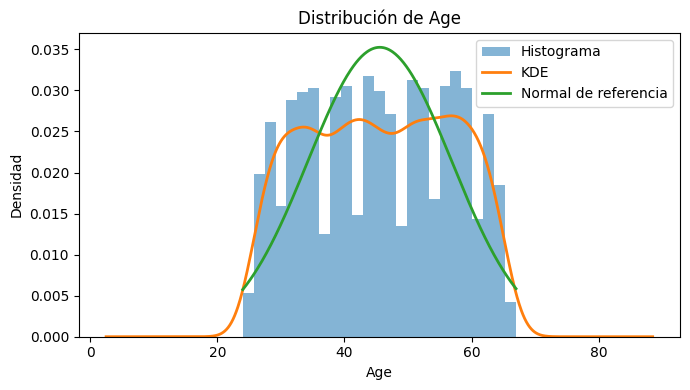

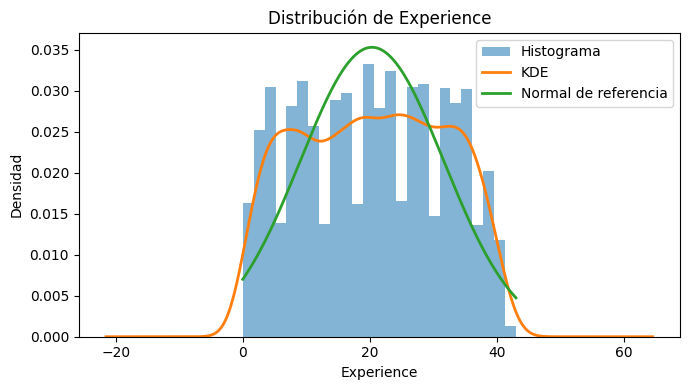

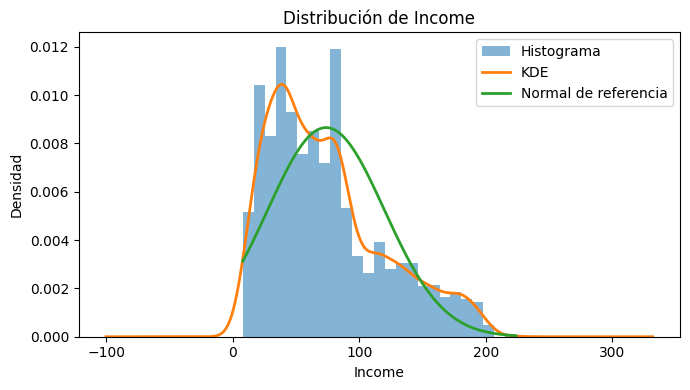

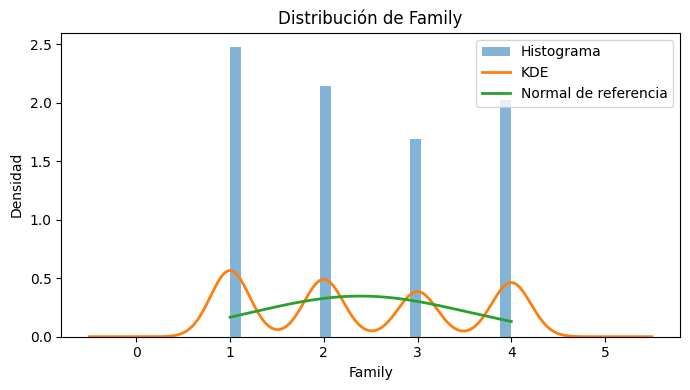

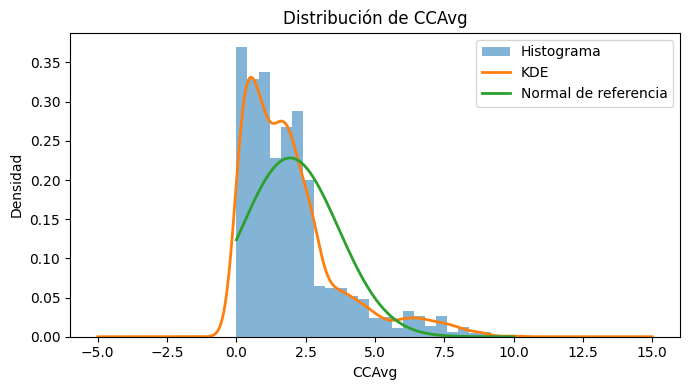

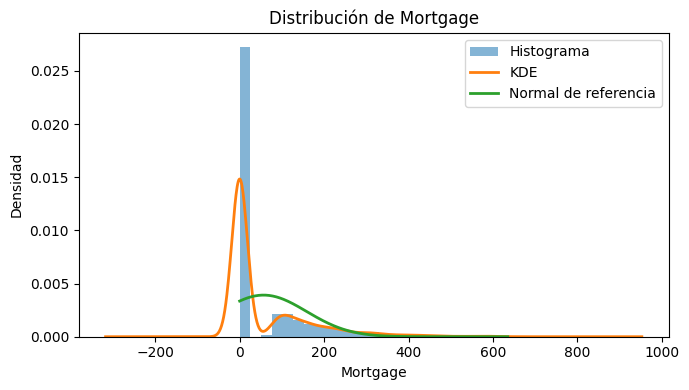

,media,mediana,skewness
Age,45.560210,46.0,-0.022754
Experience,20.335357,20.0,-0.015216
Income,73.826553,64.0,0.841991
Family,2.391621,2.0,0.159463
CCAvg,1.935855,1.5,1.594670
Mortgage,56.663631,0.0,2.103865


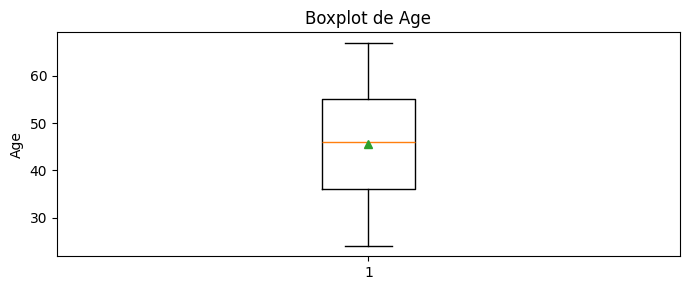

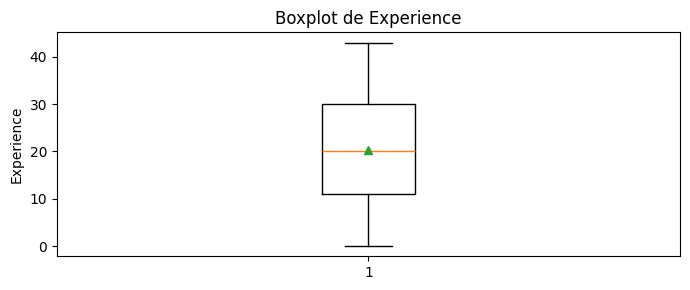

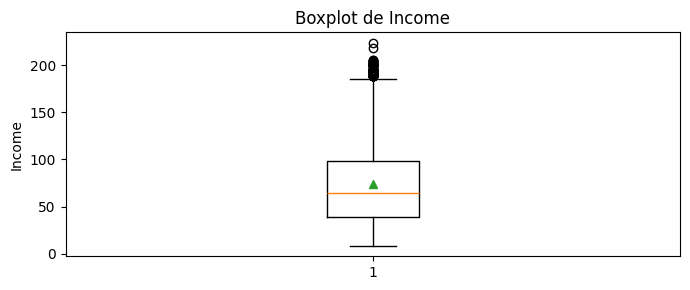

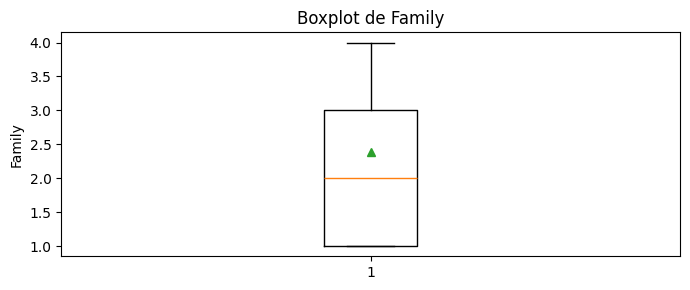

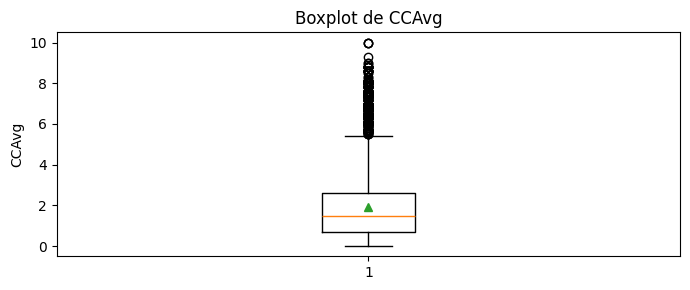

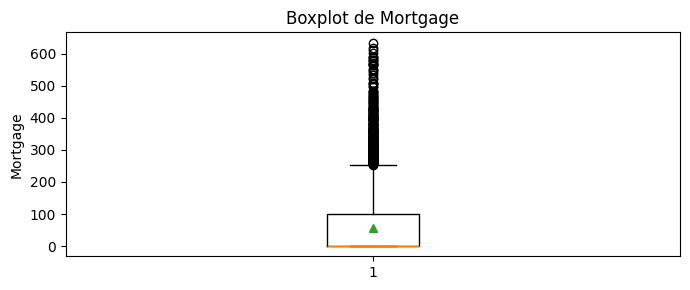

In [8]:
# Histogramas con KDE y distribución normal de referencia
for col in num_cols:
    datos = loan_df[col].dropna()
    media = datos.mean()
    desviacion = datos.std()

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(datos, bins=25, density=True, alpha=0.55, label="Histograma")
    datos.plot(kind="kde", ax=ax, linewidth=2, label="KDE")

    x = np.linspace(datos.min(), datos.max(), 300)
    ax.plot(x, norm.pdf(x, loc=media, scale=desviacion), linewidth=2, label="Normal de referencia")

    ax.set_title(f"Distribución de {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Densidad")
    ax.legend()
    plt.tight_layout()
    plt.show()
    plt.close(fig)

# Comparación media-mediana y asimetría
comparacion_central = pd.DataFrame({
    "media": loan_df[num_cols].mean(),
    "mediana": loan_df[num_cols].median(),
    "skewness": loan_df[num_cols].skew(),
})
display(comparacion_central)

# Boxplot individual para cada variable, incluyendo la media
for col in num_cols:
    fig, ax = plt.subplots(figsize=(7, 3))
    ax.boxplot(loan_df[col].dropna(), showmeans=True)
    ax.set_title(f"Boxplot de {col}")
    ax.set_ylabel(col)
    plt.tight_layout()
    plt.show()
    plt.close(fig)


**Respuesta / análisis:** Los histogramas son coherentes con las medidas numéricas. `Age` luce casi simétrica, aunque más plana que una normal, consistente con su skewness cercana a cero y curtosis negativa. `Income` muestra una cola hacia valores altos, consistente con su asimetría positiva moderada. `Mortgage` concentra muchos casos en cero y presenta una cola derecha muy larga, exactamente lo esperado por su elevada asimetría y curtosis. En los boxplots, `Age` tiene media **45.56** ligeramente menor que la mediana **46**, por lo que su sesgo es prácticamente nulo; `Income` tiene media **73.83** mayor que mediana **64**, señal de sesgo positivo; y `Mortgage` tiene media **56.66** frente a mediana **0**, evidencia de sesgo positivo muy fuerte. `CCAvg` también muestra sesgo positivo marcado (media **1.94** > mediana **1.50**).

8. Obtén las estadísticas descriptivas de las variables categóricas.
* Genera un gráfico de barras para cada variable. En las de alta cardinalidad, sólo incluye los 10 valores más relevantes.

Estadísticas descriptivas de las variables categóricas:


,count,unique,top,freq
ZIP Code,4941,467,94720,163
Education,4941,3,1,2079
Personal Loan,4941,2,0,4462
Securities Account,4941,2,0,4426
CD Account,4941,2,0,4640
Online,4941,2,1,2951
CreditCard,4941,2,0,3489


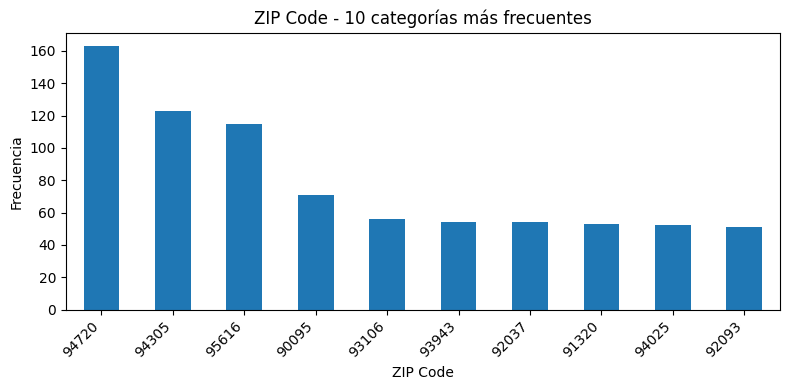

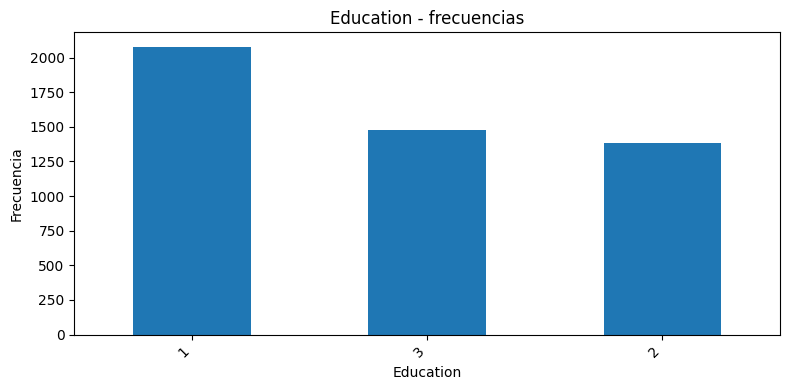

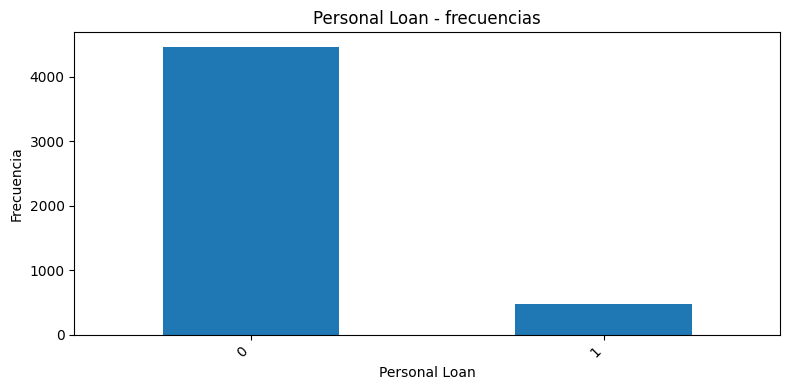

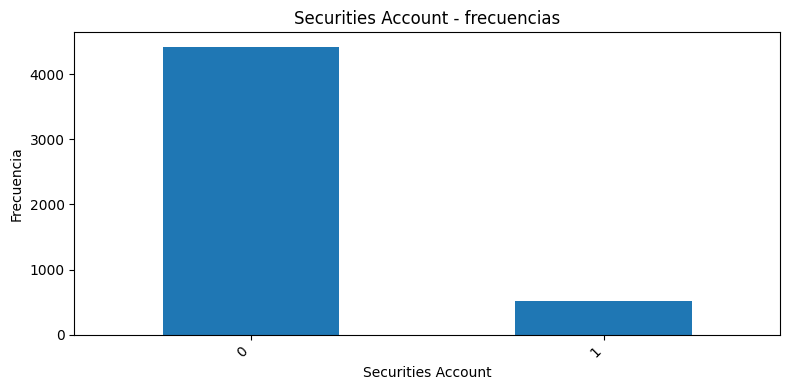

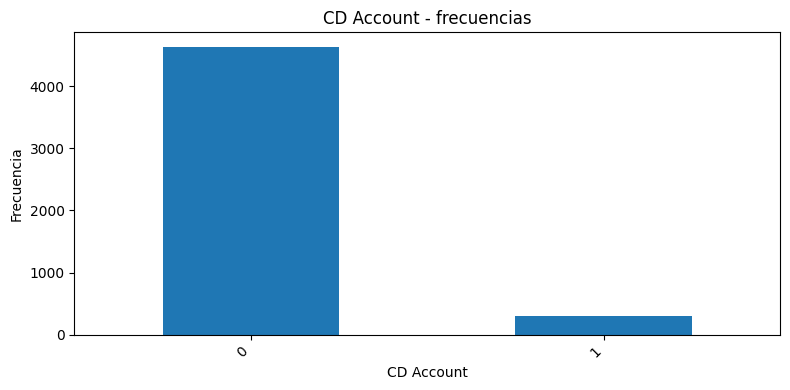

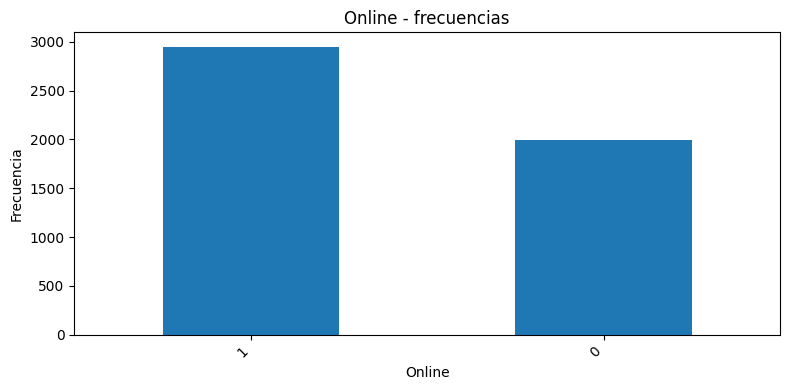

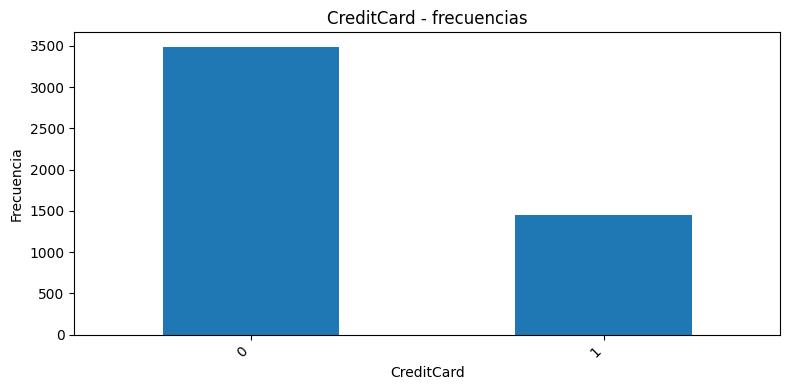

In [9]:
print("Estadísticas descriptivas de las variables categóricas:")
display(loan_df[cat_cols].describe(include="all").T)

for col in cat_cols:
    frecuencias = loan_df[col].value_counts(dropna=False)
    alta_cardinalidad = len(frecuencias) > 10

    if alta_cardinalidad:
        frecuencias = frecuencias.head(10)

    fig, ax = plt.subplots(figsize=(8, 4))
    frecuencias.plot(kind="bar", ax=ax)
    ax.set_title(
        f"{col} - {'10 categorías más frecuentes' if alta_cardinalidad else 'frecuencias'}"
    )
    ax.set_xlabel(col)
    ax.set_ylabel("Frecuencia")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
    plt.close(fig)


**Respuesta / análisis:** Entre las variables categóricas, `ZIP Code` tiene alta cardinalidad (**467 categorías**), por lo que el gráfico muestra sólo sus 10 valores más frecuentes; el código **94720** es el más común con **163 registros**. `Education` presenta 2,079 registros de nivel 1, 1,385 de nivel 2 y 1,477 de nivel 3. La variable objetivo está desbalanceada: **4,462 clientes no aceptaron** el préstamo y **479 sí lo aceptaron**, por lo que aproximadamente uno de cada diez casos pertenece a la clase positiva.

# Análisis exploratorio de datos (bivariado)

9. Obtén la matriz de gráficos de dispersión (*scatter matrix*) de todas las variables numéricas.
* Observa las relaciones entre las variables, selecciona un par representativo y describe los patrones o tendencias que sean evidentes.
* Para cuantificar la fuerza y dirección de las relaciones observadas, genera un mapa de calor con los valores de correlación de *Pearson*. ¿El valor numérico obtenido del par seleccionado se corresponde con lo esperado?

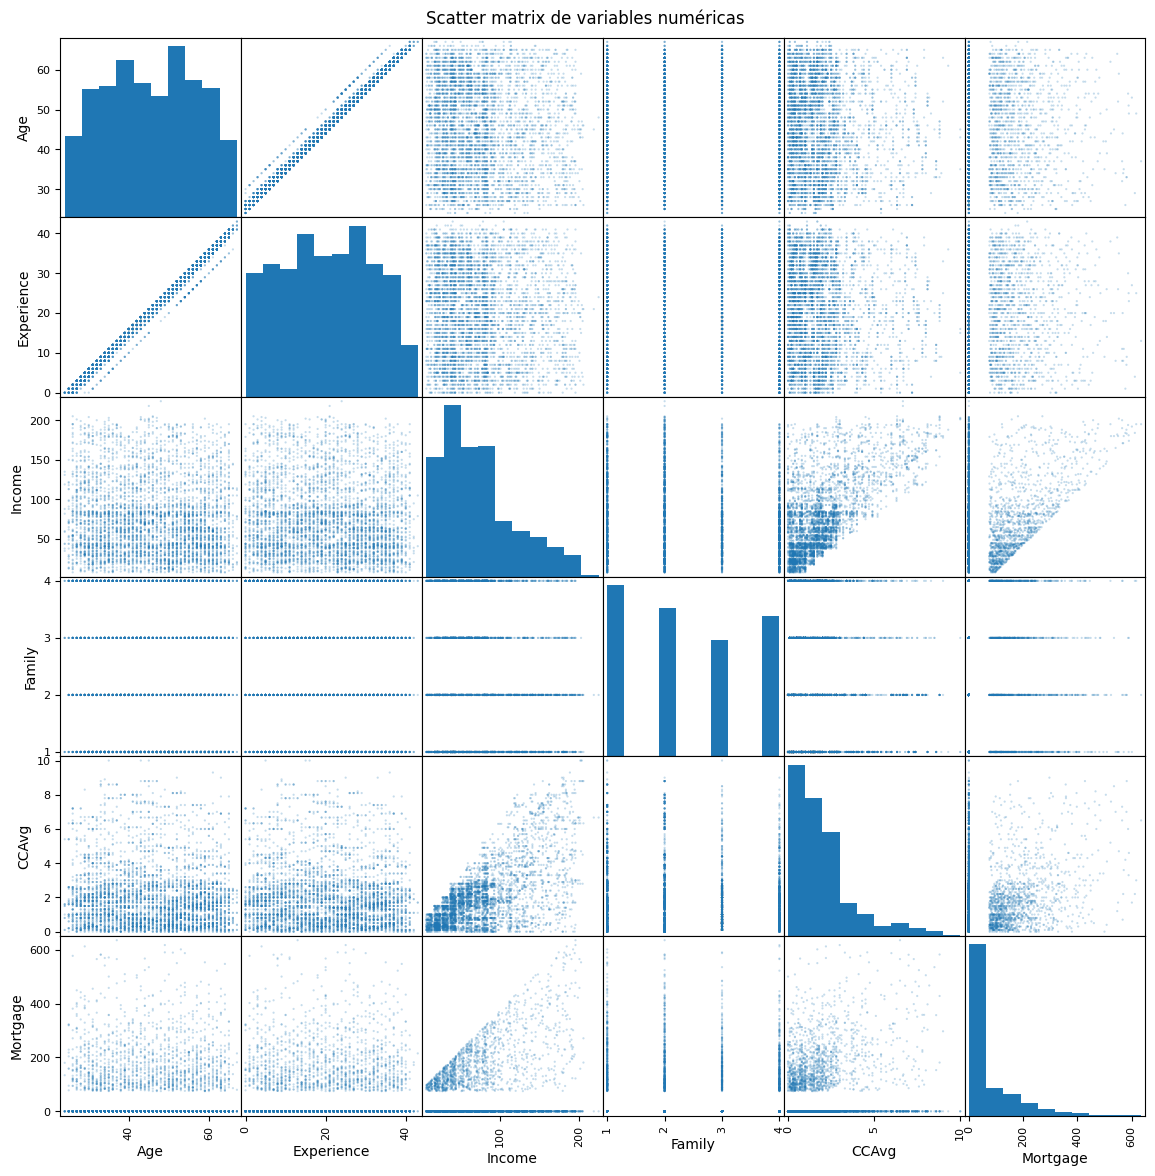

,Age,Experience,Income,Family,CCAvg,Mortgage
Age,1.000000,0.994110,-0.058281,-0.040040,-0.050919,-0.014736
Experience,0.994110,1.000000,-0.049548,-0.046487,-0.048963,-0.013078
Income,-0.058281,-0.049548,1.000000,-0.155542,0.645976,0.207231
Family,-0.040040,-0.046487,-0.155542,1.000000,-0.106822,-0.020313
CCAvg,-0.050919,-0.048963,0.645976,-0.106822,1.000000,0.110026
Mortgage,-0.014736,-0.013078,0.207231,-0.020313,0.110026,1.000000


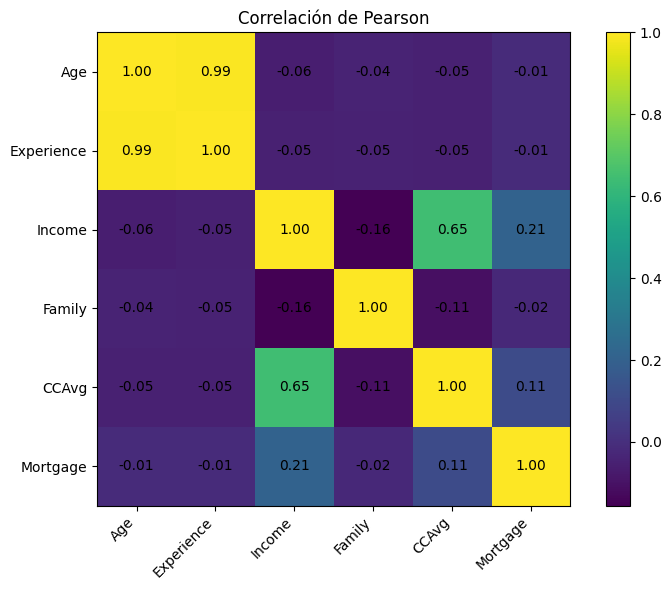

Correlación Income-CCAvg: 0.646
Correlación Age-Experience: 0.994


In [10]:
# Matriz de dispersión
axes = pd.plotting.scatter_matrix(
    loan_df[num_cols],
    figsize=(14, 14),
    diagonal="hist",
    alpha=0.25,
    s=10
)
plt.suptitle("Scatter matrix de variables numéricas", y=0.90)
plt.show()
plt.close()

# Correlaciones de Pearson
correlacion = loan_df[num_cols].corr(method="pearson")
display(correlacion)

# Mapa de calor con Matplotlib
fig, ax = plt.subplots(figsize=(8, 6))
imagen = ax.imshow(correlacion.values)

ax.set_xticks(range(len(correlacion.columns)))
ax.set_yticks(range(len(correlacion.index)))
ax.set_xticklabels(correlacion.columns, rotation=45, ha="right")
ax.set_yticklabels(correlacion.index)

for i in range(len(correlacion.index)):
    for j in range(len(correlacion.columns)):
        ax.text(j, i, f"{correlacion.iloc[i, j]:.2f}", ha="center", va="center")

fig.colorbar(imagen, ax=ax)
ax.set_title("Correlación de Pearson")
plt.tight_layout()
plt.show()
plt.close(fig)

print(
    "Correlación Income-CCAvg:",
    f"{correlacion.loc['Income', 'CCAvg']:.3f}"
)
print(
    "Correlación Age-Experience:",
    f"{correlacion.loc['Age', 'Experience']:.3f}"
)


**Respuesta / análisis:** La matriz de dispersión muestra una relación casi lineal entre `Age` y `Experience` (r ≈ **0.994**), algo razonable porque la experiencia laboral suele aumentar con la edad. Como par más útil para observar una asociación financiera, `Income` y `CCAvg` muestran una tendencia positiva moderada: conforme aumenta el ingreso también tiende a aumentar el gasto promedio con tarjeta. La correlación de Pearson entre ambas es aproximadamente **0.646**, por lo que el valor numérico concuerda con el patrón ascendente observado en la dispersión. En general, las demás correlaciones son considerablemente menores.

10. Realiza un análisis de todas las variables del dataset con respecto a la variable de salida `Personal Loan`.
* Variables numéricas: Genera box plots para comparar la distribución de cada variable según los valores de `Personal Loan`.
* Variables categóricas (sin considerar `ZIP Code`): Genera gráficos de barras apiladas que muestren la distribución relativa de `Personal Loan` dentro de cada categoría de la variable.
* Para cada grupo de variables (numéricas y categóricas), comenta al menos un hallazgo o patrón relevante observado en los gráficos generados.


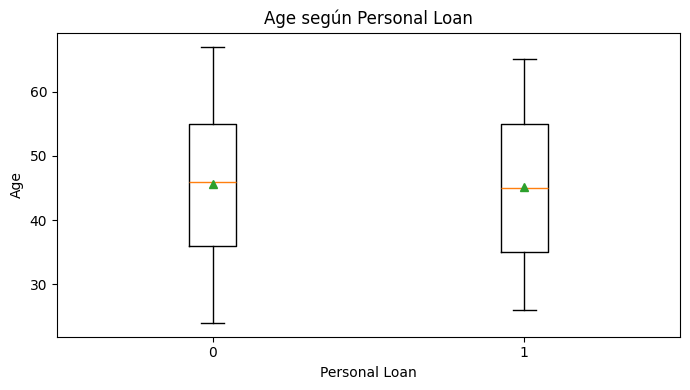

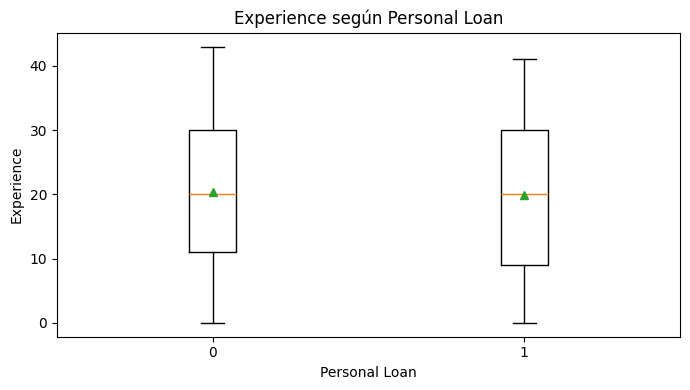

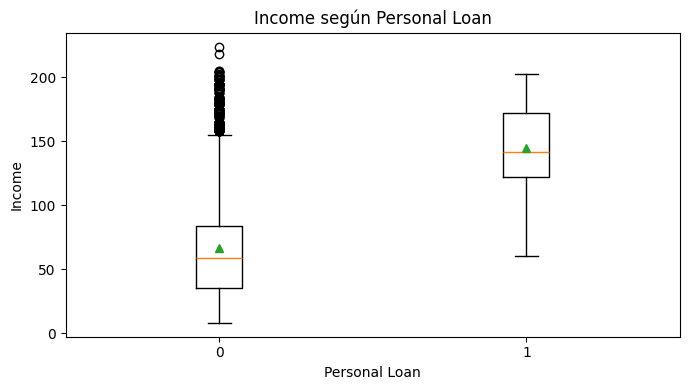

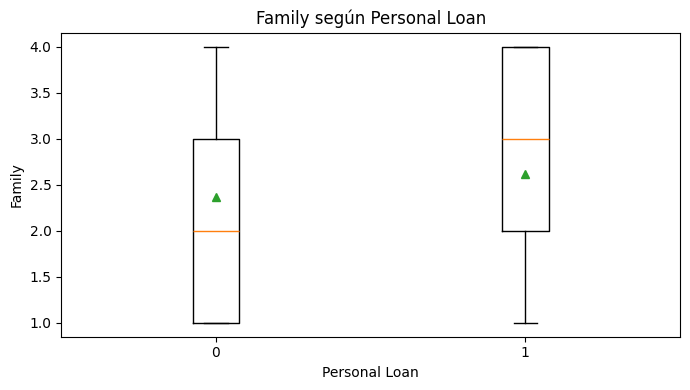

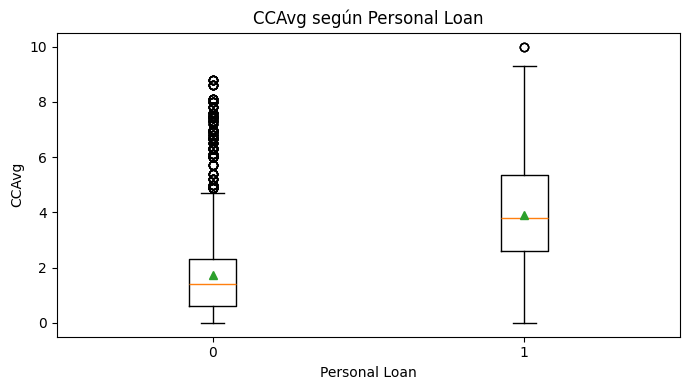

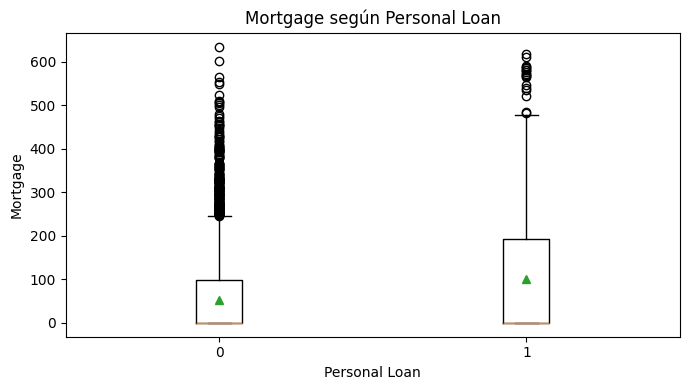

Medias de variables numéricas por Personal Loan:


,Age,Experience,Income,Family,CCAvg,Mortgage
Personal Loan,,,,,,
0,45.612,20.387,66.218,2.368,1.725,51.898
1,45.077,19.856,144.706,2.616,3.905,101.056


Medianas de variables numéricas por Personal Loan:


,Age,Experience,Income,Family,CCAvg,Mortgage
Personal Loan,,,,,,
0,46.0,20.0,59.0,2.0,1.4,0.0
1,45.0,20.0,142.0,3.0,3.8,0.0


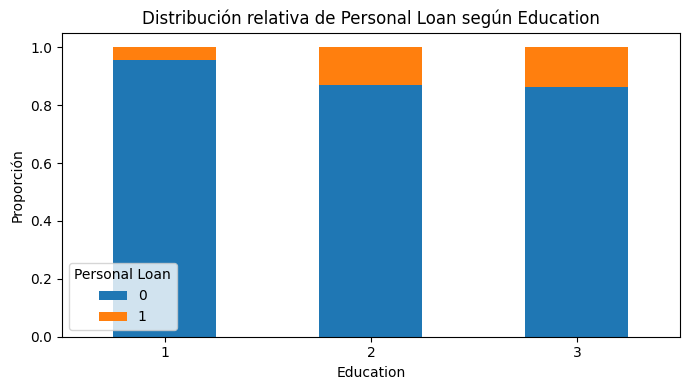

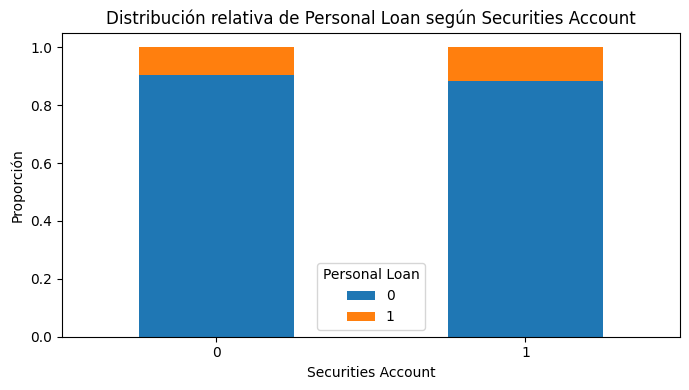

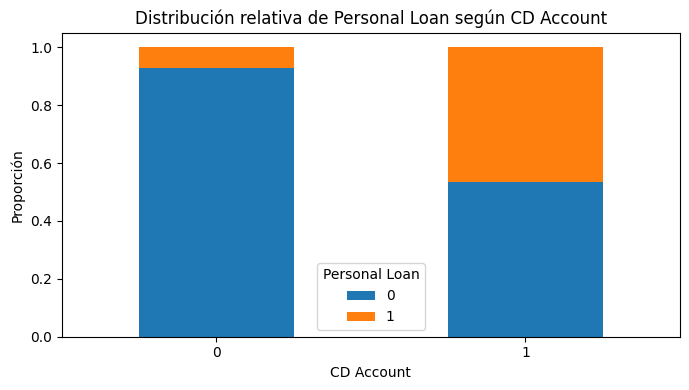

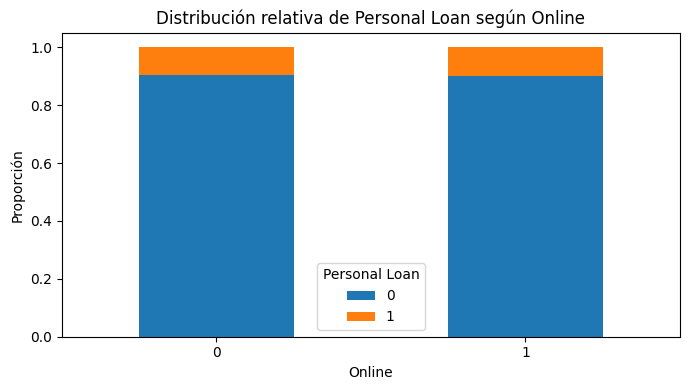

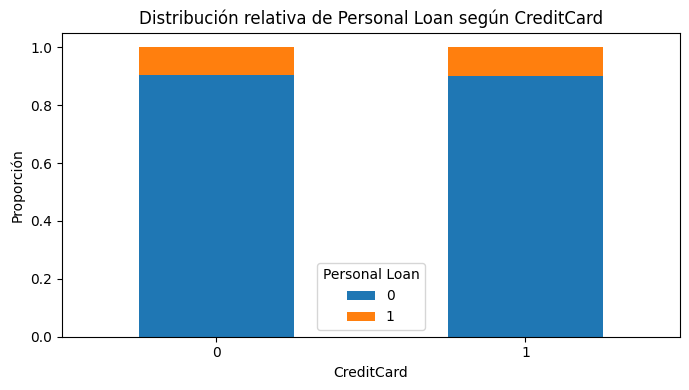


Distribución relativa para Education:


Personal Loan,0,1
Education,,
1,0.9553,0.0447
2,0.8693,0.1307
3,0.8612,0.1388



Distribución relativa para Securities Account:


Personal Loan,0,1
Securities Account,,
0,0.9053,0.0947
1,0.8835,0.1165



Distribución relativa para CD Account:


Personal Loan,0,1
CD Account,,
0,0.9269,0.0731
1,0.5349,0.4651



Distribución relativa para Online:


Personal Loan,0,1
Online,,
0,0.9055,0.0945
1,0.9014,0.0986



Distribución relativa para CreditCard:


Personal Loan,0,1
CreditCard,,
0,0.9037,0.0963
1,0.9015,0.0985


In [11]:
# Variables numéricas vs. Personal Loan
for col in num_cols:
    grupo_0 = loan_df.loc[loan_df["Personal Loan"] == 0, col].dropna()
    grupo_1 = loan_df.loc[loan_df["Personal Loan"] == 1, col].dropna()

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.boxplot([grupo_0, grupo_1], tick_labels=["0", "1"], showmeans=True)
    ax.set_title(f"{col} según Personal Loan")
    ax.set_xlabel("Personal Loan")
    ax.set_ylabel(col)
    plt.tight_layout()
    plt.show()
    plt.close(fig)

print("Medias de variables numéricas por Personal Loan:")
display(
    loan_df.groupby("Personal Loan", observed=True)[num_cols]
    .mean()
    .round(3)
)

print("Medianas de variables numéricas por Personal Loan:")
display(
    loan_df.groupby("Personal Loan", observed=True)[num_cols]
    .median()
    .round(3)
)

# Variables categóricas vs. Personal Loan, excluyendo ZIP Code y el propio target.
cat_predictoras = [
    col for col in cat_cols
    if col not in ["ZIP Code", "Personal Loan"]
]

for col in cat_predictoras:
    tabla_relativa = pd.crosstab(
        loan_df[col],
        loan_df["Personal Loan"],
        normalize="index"
    )

    fig, ax = plt.subplots(figsize=(7, 4))
    tabla_relativa.plot(kind="bar", stacked=True, ax=ax)
    ax.set_title(f"Distribución relativa de Personal Loan según {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Proporción")
    ax.legend(title="Personal Loan")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
    plt.close(fig)

# Tasas de aceptación para apoyar la interpretación
for col in cat_predictoras:
    tasa = pd.crosstab(
        loan_df[col],
        loan_df["Personal Loan"],
        normalize="index"
    )
    print(f"\nDistribución relativa para {col}:")
    display(tasa.round(4))


**Respuesta / análisis:** En las variables numéricas, el patrón más claro se observa en `Income`: quienes aceptaron el préstamo tienen ingreso promedio de aproximadamente **144.71 mil USD/año**, frente a **66.22 mil USD/año** entre quienes no lo aceptaron; las medianas son **142** y **59**, respectivamente. También presentan mayor `CCAvg` promedio (**3.90** frente a **1.72**) y mayor hipoteca promedio (**101.06** frente a **51.90**), mientras que `Age` y `Experience` cambian muy poco entre ambos grupos.

En las variables categóricas, `CD Account` presenta la diferencia más marcada: aproximadamente **46.5%** de los clientes con CD Account aceptaron el préstamo, frente a sólo **7.3%** de quienes no tienen esa cuenta. `Education` también muestra diferencias: la proporción de aceptación es cercana a **4.5%** para nivel 1 y alrededor de **13–14%** para niveles 2 y 3. En cambio, `Online` y `CreditCard` muestran tasas de aceptación muy similares entre sus categorías, por lo que visualmente parecen tener poca relación individual con la respuesta.

---

**Declaración de uso de IA**

OpenAI. (2026). *ChatGPT (GPT-5.6 Sol)* [Modelo de lenguaje grande], utilizado como apoyo para generación de código, depuración y optimización de la solución, así como para estructurar las explicaciones del análisis exploratorio de datos.

La revisión, ejecución y responsabilidad final del contenido presentado corresponden al autor.

https://chatgpt.com/

---